# TP5 — Partie B.2 : Chatbot Agentic RAG avec LangGraph

Objectifs :
1. Développer un chatbot **Agentic RAG** avec LangGraph ;
2. Le tester avec **LangGraph Studio** ;
3. Lui donner une interface web **Streamlit**.

Le graphe est écrit dans un module Python réutilisable, pour être servi à la fois par ce notebook, par LangGraph Studio et par Streamlit :

```
partie_B_langgraph/
├── agentic_rag/
│   ├── rag.py        # base de connaissances : PDF → chunks → CLIP (Chroma) + BM25 → recherche hybride
│   └── graph.py      # StateGraph : agent ⇄ tools (retriever_tool) + export `graph`
├── langgraph.json    # configuration LangGraph Studio (langgraph dev)
└── app_streamlit.py  # interface web
```

**Base de connaissances :** le support de cours *« Agentic AI et MCP »* (PDF).
**RAG agentique :** la recherche est un *tool* : le LLM décide **s'il** cherche, **quoi** chercher (reformulation) et s'il doit **relancer** une recherche.

## 1. Base de connaissances et `retriever_tool`

In [1]:
import logging
from agentic_rag.rag import base_connaissances
from agentic_rag.graph import retriever_tool, build_graph, graph, SYSTEM_PROMPT

logging.getLogger("agentic_rag").setLevel(logging.INFO)

kb = base_connaissances()
print(f"{len(kb.chunks)} chunks indexés (CLIP + BM25)")

/Users/hajdaoui/IA GENERATIVE MULTI-MODALE/TP5/.venv/lib/python3.11/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


/Users/hajdaoui/IA GENERATIVE MULTI-MODALE/TP5/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


58 chunks indexés (CLIP + BM25)


In [2]:
# Test manuel du tool (Step 5 du cours : test du retrieval)
print(retriever_tool.invoke({"query": "format des messages MCP protocol messages JSON"})[:900])

[page 11] •
The protocol uses JSON-RPC 2.0 messages
•
The protocol defines two standard transport mechanisms for client-server communication:
•
STDIO, communication over standard input and standard output
•
SSE (Server Sent Event : serveur→client en streaming + POST séparés pour client→serveur
•

[page 11] A2A
Streamable HTTP
stdio
SSE 
Local Sub Process
Streamable HTTP
Local Sub Process
stdio
SSE 
•
MCP standardizes how to integrate additional context and tools into the ecosystem of AI applications 
•
The protocol uses JSON-RPC 2.0 messages
•

[page 4] )
print(res['messages'][-1].content)
res=agent.invoke(
  input={'messages':[HumanMessage('What is my name')]},
  config={'configurable':{'thread_id':1}}
)
print(res['messages'][-1].content)

[page 3] timeout=30
)
Implémentation d’un agent Langchain
response=agent.invoke(
  input={
    'messages’:[
       HumanMessage('weather in Marrakech


## 2. Le graphe

`START → agent → (tool_calls ? tools : END)` et `tools → agent` (boucle ReAct).

**Garde-fous du nœud `agent`** (spécifiques au modèle local `qwen3-vl:8b`, de type *thinking*) :
- le parser Ollama `qwen3-vl-thinking` range parfois l'appel d'outil écrit par le modèle **dans son raisonnement** : la réponse arrive vide, sans `tool_calls`. Le nœud récupère alors cet appel (`tool_call_dans_raisonnement`) et le transforme en véritable `tool_call` ;
- si la réponse reste vide, nouvelles tentatives avec un modèle à température 0,6 (à température 0, l'échec se reproduirait à l'identique) ;
- `num_predict=2048` coupe une réflexion qui s'emballe.

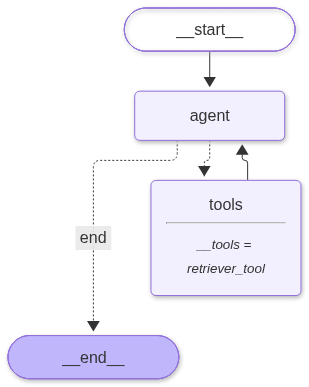

In [3]:
from IPython.display import Image, Markdown, display
display(Image(graph.get_graph().draw_mermaid_png()))

## 3. Exécution

On affiche la trace : décisions de l'agent (journalisées par le nœud `agent`), appels du tool et réponse finale.

In [4]:
from langchain.messages import HumanMessage, AIMessage, ToolMessage


def trace(resp, debut=0):
    for m in resp["messages"][debut:]:
        if isinstance(m, AIMessage) and m.tool_calls:
            for tc in m.tool_calls:
                print(f"🛠  {tc['name']}({tc['args']})")
        elif isinstance(m, ToolMessage):
            pages = sorted({l.split(']')[0] + ']' for l in m.content.split('\n') if l.startswith('[page')})
            print(f"👁  passages : {', '.join(pages)}")
    display(Markdown("**Réponse :** " + resp["messages"][-1].content))


resp = graph.invoke({"messages": [HumanMessage("Quels sont les mécanismes de transport définis par MCP ?")]})
trace(resp)

21:26:49 [INFO] AGENT NODE : appel du LLM avec 1 message(s)


21:27:57 [INFO]    ✓ décision : retriever_tool({'query': 'mécanismes de transport MCP transport mechanisms protocol'})


21:27:57 [INFO] 🔀 ROUTAGE → tools


21:27:58 [INFO] AGENT NODE : appel du LLM avec 3 message(s)


21:28:09 [INFO]    ✓ réponse finale générée


21:28:09 [INFO] 🔀 ROUTAGE → END


🛠  retriever_tool({'query': 'mécanismes de transport MCP transport mechanisms protocol'})
👁  passages : [page 11], [page 13], [page 15], [page 16], [page 17]


**Réponse :** Les mécanismes de transport définis par MCP sont :  
- **STDIO** : communication via les entrées/sorties standard.  
- **SSE (Server Sent Events)** : flux en temps réel serveur→client avec des POST séparés pour client→serveur.  

Ces mécanismes sont définis dans le protocole JSON-RPC 2.0 [page 11].

In [5]:
resp = graph.invoke({"messages": [HumanMessage("Quelle est la différence entre LangChain et LangGraph ?")]})
trace(resp)

21:28:09 [INFO] AGENT NODE : appel du LLM avec 1 message(s)


21:28:17 [INFO]    ✓ décision : retriever_tool({'query': 'LangChain LangGraph différence difference architecture state management'})


21:28:17 [INFO] 🔀 ROUTAGE → tools


21:28:17 [INFO] AGENT NODE : appel du LLM avec 3 message(s)


21:28:34 [INFO]    ✓ réponse finale générée


21:28:34 [INFO] 🔀 ROUTAGE → END


🛠  retriever_tool({'query': 'LangChain LangGraph différence difference architecture state management'})
👁  passages : [page 1], [page 4], [page 5], [page 7]


**Réponse :** LangChain est un framework pour construire des applications avec des modèles LLM, gérant les agents, la mémoire et les outils. LangGraph, quant à lui, est un outil spécialisé dans la gestion d'états et l'orchestration de workflows graphiques au sein de LangChain.  

- **LangGraph** est préférable pour les systèmes nécessitant une prévisibilité (workflows déterministes), le checkpointing et le déploiement en production ([page 5]).  
- Il intègre des fonctionnalités comme le débogage avec LangSmith et LangGraph Studio ([page 5]).  
- L'implémentation d'un agent LangGraph utilise des nœuds (State, Tools, LLM) pour structurer les étapes ([page 7]).  

LangChain reste le framework principal, tandis que LangGraph sert à optimiser les workflows complexes et déterministes ([page 4]).

## 4. Chatbot avec mémoire

On compile le **même** graphe avec un `InMemorySaver` : la conversation est conservée par `thread_id` (questions de suivi, prénom…).

In [6]:
from langgraph.checkpoint.memory import InMemorySaver

chatbot = build_graph(checkpointer=InMemorySaver())


def chat(question, thread_id="conversation-1"):
    config = {"configurable": {"thread_id": thread_id}}
    debut = len(chatbot.get_state(config).values.get("messages", [])) + 1
    print(f"👤 {question}")
    trace(chatbot.invoke({"messages": [HumanMessage(question)]}, config=config), debut)
    print("-" * 80)


chat("Bonjour, je suis Sara, étudiante en IA générative")
chat("Qu'est-ce que le pattern ReAct ?")
chat("Et quels outils permettent de tester un serveur MCP ?")
chat("Quel est le prix d'un iPhone ?")
chat("Rappelle-moi mon prénom et ma formation")

21:28:34 [INFO] AGENT NODE : appel du LLM avec 1 message(s)


👤 Bonjour, je suis Sara, étudiante en IA générative


21:28:39 [INFO]    ✓ réponse finale générée


21:28:39 [INFO] 🔀 ROUTAGE → END


**Réponse :** Bonjour Sara ! Enchanté de t'aider dans ton parcours en IA générative. N'hésite pas à poser des questions sur le cours « Agentic AI et MCP » — je suis là pour t'accompagner. 😊

21:28:39 [INFO] AGENT NODE : appel du LLM avec 3 message(s)


... (22 outputs left out)

21:30:48 [INFO]    ✓ réponse finale générée


21:30:48 [INFO] 🔀 ROUTAGE → END


**Réponse :** Sara, étudiante en IA générative.

--------------------------------------------------------------------------------


## 5. Streaming des étapes

`stream_mode="updates"` renvoie la mise à jour produite par **chaque nœud** : c'est ce qu'utilise l'interface Streamlit pour afficher la progression.

In [7]:
for etape in graph.stream({"messages": [HumanMessage("Comment ajouter une mémoire à un agent LangGraph ?")]},
                          stream_mode="updates"):
    for noeud, maj in etape.items():
        m = maj["messages"][-1]
        resume = m.tool_calls if getattr(m, "tool_calls", None) else str(m.content)[:150]
        print(f"[{noeud}] {resume}")

21:30:48 [INFO] AGENT NODE : appel du LLM avec 1 message(s)


21:30:58 [INFO]    ✓ décision : retriever_tool({'query': 'mémoire LangGraph memory LangGraph'})


21:30:58 [INFO] 🔀 ROUTAGE → tools


21:30:58 [INFO] AGENT NODE : appel du LLM avec 3 message(s)


[agent] [{'name': 'retriever_tool', 'args': {'query': 'mémoire LangGraph memory LangGraph'}, 'id': 'e2b33ca5-6195-4119-a1fb-857c9b7bc45c', 'type': 'tool_call'}]
[tools] [page 10] Implémentation d’un agent Langgraph : Memory
from langgraph.checkpoint.memory import InMemorySaver
Run The workflow
memory = InMemorySaver()


21:31:16 [INFO]    ✓ réponse finale générée


21:31:16 [INFO] 🔀 ROUTAGE → END


[agent] Pour ajouter une mémoire à un agent LangGraph, utilisez l'outil `InMemorySaver` comme indiqué :

1. Importez le module :  
   `from langgraph.checkpoi


## 6. Test avec LangGraph Studio

`langgraph.json` déclare le graphe `agentic_rag` (`./agentic_rag/graph.py:graph`) et le fichier `.env`.
On lance le serveur de développement depuis `partie_B_langgraph/` :

```bash
uv run langgraph dev
```

Le serveur expose l'API LangGraph sur `http://127.0.0.1:2024` et LangGraph Studio s'ouvre dans le navigateur
(`https://smith.langchain.com/studio/?baseUrl=http://127.0.0.1:2024`) : on y visualise le graphe, on envoie des messages et on suit l'exécution nœud par nœud.

On teste ici le **même serveur** par programme avec le SDK `langgraph_sdk` (threads, runs, état persistant) :

In [8]:
from langgraph_sdk import get_client

client = get_client(url="http://127.0.0.1:2024")
assistants = await client.assistants.search()
print("graphes servis :", [a["graph_id"] for a in assistants])

thread = await client.threads.create()
for question in ["Que signifie l'acronyme MCP ? Réponds en une phrase.", "Quels transports propose-t-il ?"]:
    etat = await client.runs.wait(thread["thread_id"], "agentic_rag",
                                  input={"messages": [{"role": "user", "content": question}]})
    print(f"👤 {question}\n🤖 {etat['messages'][-1]['content']}\n")

historique = await client.threads.get_state(thread["thread_id"])
print("messages persistés dans le thread :", len(historique["values"]["messages"]))

graphes servis : ['agentic_rag']


👤 Que signifie l'acronyme MCP ? Réponds en une phrase.
🤖 L'acronyme MCP signifie Model Context Protocol [page 14].



👤 Quels transports propose-t-il ?
🤖 MCP propose le transport "streamable-http" [page 13].

messages persistés dans le thread : 6


### Captures LangGraph Studio

Graphe servi par `langgraph dev` :

![Studio — graphe](captures/studio_1_graphe.png)

Exécution en direct : `agent` décide d'appeler `retriever_tool`, `tools` exécute la recherche, puis `agent` répond :

![Studio — exécution](captures/studio_2_execution.png)

Détail du tour : la question, et la requête **reformulée** en français + anglais par l'agent :

![Studio — appel du tool](captures/studio_3_appel_retriever_tool.png)

Passages récupérés (page 11) et réponse finale sourcée « JSON-RPC 2.0 [page 11] » :

![Studio — passages et réponse](captures/studio_4_passages_et_reponse.png)

## 7. Interface web Streamlit

`app_streamlit.py` compile le graphe avec un `InMemorySaver` (un `thread_id` par session), affiche la progression grâce à `graph.stream(..., stream_mode="updates")` et montre dans un encart les requêtes et passages utilisés.

```bash
cd partie_B_langgraph
uv run streamlit run app_streamlit.py
```

### Captures de l'interface Streamlit

Accueil (barre latérale : session, `thread_id`, architecture) :

![Streamlit — accueil](captures/streamlit_1_accueil.png)

Conversation : salutation, question sur le cours, statut de l'agent, réponse sourcée et encart des recherches effectuées :

![Streamlit — conversation](captures/streamlit_2_conversation.png)